# ROC-AUC vs PR-AUC

Logistic regression and the tuned LightGBM on valid: ROC and precision–recall curves, and how much fraud each model
catches at a fixed share of false alarms.

In [1]:
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score

from fraud.data import load_train
from fraud.features import add_features
from fraud.models import make_lightgbm, make_logreg
from fraud.split import time_split

In [2]:
df = add_features(load_train())
train, valid, _ = time_split(df)

NON_FEATURES = ["isFraud", "TransactionDT", "TransactionID"]
X_train, y_train = train.drop(columns=NON_FEATURES), train["isFraud"]
X_valid, y_valid = valid.drop(columns=NON_FEATURES), valid["isFraud"]

LR_COLS = [c for c in X_train.columns if not c.startswith("V")]
CAT_COLS = X_train[LR_COLS].select_dtypes("category").columns.tolist()
NUM_COLS = [c for c in LR_COLS if c not in CAT_COLS]

In [3]:
logreg = make_logreg(NUM_COLS, CAT_COLS)
logreg.fit(X_train, y_train)

lgbm = make_lightgbm(seed=42, n_jobs=8)
lgbm.fit(X_train, y_train, eval_X=X_valid, eval_y=y_valid, callbacks=[lgb.early_stopping(100, verbose=False)])

SCORES = {
    "Logistic regression": logreg.predict_proba(X_valid)[:, 1],
    "LightGBM": lgbm.predict_proba(X_valid)[:, 1],
}
for name, scores in SCORES.items():
    print(f"{name}: ROC-AUC {roc_auc_score(y_valid, scores):.4f}   PR-AUC {average_precision_score(y_valid, scores):.4f}")

Logistic regression: ROC-AUC 0.8201   PR-AUC 0.2998
LightGBM: ROC-AUC 0.9351   PR-AUC 0.6540


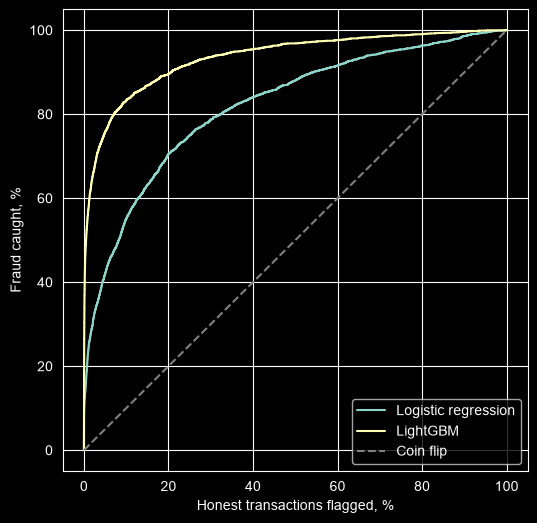

In [4]:
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(6, 6))
for name, scores in SCORES.items():
    fpr, recall, _ = roc_curve(y_valid, scores)
    ax.plot(fpr * 100, recall * 100, label=name)
ax.plot([0, 100], [0, 100], color="gray", linestyle="--", label="Coin flip")
ax.set_xlabel("Honest transactions flagged, %")
ax.set_ylabel("Fraud caught, %")
ax.legend()
plt.show()

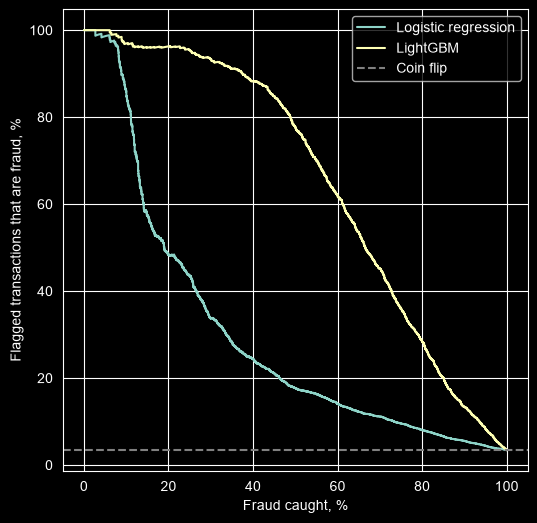

In [5]:
from sklearn.metrics import precision_recall_curve

fig, ax = plt.subplots(figsize=(6, 6))
for name, scores in SCORES.items():
    precision, recall, _ = precision_recall_curve(y_valid, scores)
    ax.plot(recall * 100, precision * 100, label=name)
ax.axhline(y_valid.mean() * 100, color="gray", linestyle="--", label="Coin flip")
ax.set_xlabel("Fraud caught, %")
ax.set_ylabel("Flagged transactions that are fraud, %")
ax.legend()
plt.show()

On ROC both models look good (ROC-AUC 0.820 and 0.935) and differ mostly at many false alarms. On PR the gap is
large: to catch half of the fraud, about three in four LightGBM alerts are real, against fewer than one in five for
logistic regression. ROC hides this because honest transactions outnumber fraud 28 to 1, so a few percent of false
alarms on the ROC axis means thousands of honest customers. With rare fraud, PR-AUC is the main metric.

In [6]:
n_fraud, n_honest = y_valid.sum(), (y_valid == 0).sum()

for name, scores in SCORES.items():
    fpr, recall, _ = roc_curve(y_valid, scores)
    best = recall[fpr <= 0.01].max()
    print(f"{name}: catches {best:.1%} of fraud ({best * n_fraud:.0f} of {n_fraud}) "
          f"while flagging 1% of honest transactions (~{0.01 * n_honest:.0f})")

Logistic regression: catches 23.5% of fraud (671 of 2850) while flagging 1% of honest transactions (~807)
LightGBM: catches 56.9% of fraud (1621 of 2850) while flagging 1% of honest transactions (~807)


With 1% of honest transactions flagged (about 807 customers in valid), LightGBM catches 56.9% of fraud (1,621 of
2,850) and logistic regression 23.5% (671): 2.4 times more fraud for the same number of disturbed customers, and
about two in three LightGBM alerts are real. Catching more fraud means flagging more honest customers; where to
stop is decided later from the cost of each kind of error.

## Summary

| Model | Columns | ROC-AUC | PR-AUC | Fraud caught at 1% false alarms |
|---|---|---|---|---|
| Random guess | – | 0.500 | 0.034 | 1% |
| Logistic regression | 101 | 0.820 | 0.300 | 23.5% |
| Random forest | 101 | 0.905 | 0.489 | – |
| CatBoost | 440 | 0.912 | 0.602 | – |
| LightGBM, 300 trees | 440 | 0.928 | 0.607 | – |
| LightGBM, early stopping | 440 | 0.931 | 0.648 | – |
| LightGBM, tuned | 440 | 0.934 | 0.659 | 56.9% |

Valid month; means over seeds 42, 1, 2 (the last column: seed 42). Across the real models ROC-AUC spans 0.82–0.93,
while PR-AUC spans 0.30–0.66.